In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/satoru3825/tweet-sentiment-data/preprocess.py
/kaggle/input/datasets/satoru3825/tweet-sentiment-data/test.csv
/kaggle/input/datasets/satoru3825/tweet-sentiment-data/train.csv
/kaggle/input/datasets/satoru3825/tweet-sentiment-data/validation.csv
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/__huggingface_repos__.json
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/__notebook__.ipynb
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/__output__.json
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/__results__.html
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/custom.css
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/training_info.json
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/training_log.csv
/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/validation_per_epoch.csv
/kaggle/input

In [2]:
import sys
import transformers
import torch
import glob

DATA = "/kaggle/input/datasets/satoru3825/tweet-sentiment-data" 
print(glob.glob("/kaggle/input/**/preprocess.py", recursive=True))
print(glob.glob("/kaggle/input/**/final_model/config.json", recursive=True))

sys.path.insert(0, DATA)
from preprocess import clean_tweet, preprocess

test_df = preprocess(pd.read_csv(f"{DATA}/test.csv"))

print(test_df.shape)
print(test_df["label"].value_counts())
print("transformers:", transformers.__version__, "| torch:", torch.__version__)

test_df[["tweet", "clean_tweet", "label"]].head()

['/kaggle/input/datasets/satoru3825/tweet-sentiment-data/preprocess.py']
['/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/final_model/config.json']
(20000, 4)
label
0    10000
1    10000
Name: count, dtype: int64
transformers: 5.20.2 | torch: 2.11.0+cu130


,tweet,clean_tweet,label
0,@disappointment http://twitpic.com/7sxp2 - You...,USER URL - you have a friday *axe*? our office...,0
1,dropped my laptop on the bridge ov my nose can...,dropped my laptop on the bridge ov my nose can...,0
2,Goin' to bed... but not without my Kradam sear...,goin' to bed... but not without my kradam sear...,1
3,"Friday, payday! Or more like, bill paying day","friday, payday! or more like, bill paying day",0
4,Um.. I want Brutal Legend so retardedly bad no...,um.. i want brutal legend so retardedly bad no...,1


In [3]:
from datasets import Dataset
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification

MODEL_DIR = "/kaggle/input/notebooks/satoru3825/distilbert-tweet-sentiment-training/final_model"
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)

print(model.config.id2label)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{0: 'negative', 1: 'positive'}


In [4]:
from transformers import DataCollatorWithPadding

def to_dataset(df):
    encodings = tokenizer(df["clean_tweet"].tolist(), truncation=True, max_length=64)
    return Dataset.from_dict({
        "input_ids": encodings["input_ids"],
        "attention_mask": encodings["attention_mask"],
        "labels": df["label"].tolist(),
    })
    
test_ds = to_dataset(test_df)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(test_ds[:3])

{'input_ids': [[101, 5310, 24471, 2140, 1011, 2017, 2031, 1037, 5958, 1008, 12946, 1008, 1029, 2256, 2436, 2003, 4659, 9996, 24802, 102], [101, 3333, 2026, 12191, 2006, 1996, 2958, 1051, 2615, 2026, 4451, 2064, 2514, 1037, 15116, 3504, 18618, 7910, 2232, 2821, 23644, 22038, 2595, 102], [101, 17249, 1005, 2000, 2793, 1012, 1012, 1012, 2021, 2025, 2302, 2026, 1047, 28510, 2213, 3945, 2005, 1996, 5353, 1012, 1012, 1012, 102]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], 'labels': [0, 0, 1]}


In [5]:
import time
from transformers import Trainer

predictor = Trainer(
    model=model,
    processing_class=tokenizer,
    data_collator=data_collator,
)

start = time.perf_counter()
output = predictor.predict(test_ds)
elapsed = time.perf_counter() - start
print(f"prediction time: {elapsed:.1f} seconds")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


prediction time: 51.1 seconds


In [6]:
logits = output.predictions
test_predict = np.argmax(logits, axis=-1)
prob_positive = torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()

print(logits.shape)
print(test_predict[:10])
print(prob_positive[:5].round(3))
print(output.metrics)

(20000, 2)
[0 0 0 1 0 1 0 1 1 0]
[0.034 0.012 0.159 0.689 0.464]
{'test_loss': 0.6954061388969421, 'test_runtime': 51.0463, 'test_samples_per_second': 391.801, 'test_steps_per_second': 24.488}


test accuracy:   0.8498
test F1 (macro): 0.8498
              precision    recall  f1-score   support

    negative       0.84      0.86      0.85     10000
    positive       0.86      0.84      0.85     10000

    accuracy                           0.85     20000
   macro avg       0.85      0.85      0.85     20000
weighted avg       0.85      0.85      0.85     20000

[[8581 1419]
 [1585 8415]]


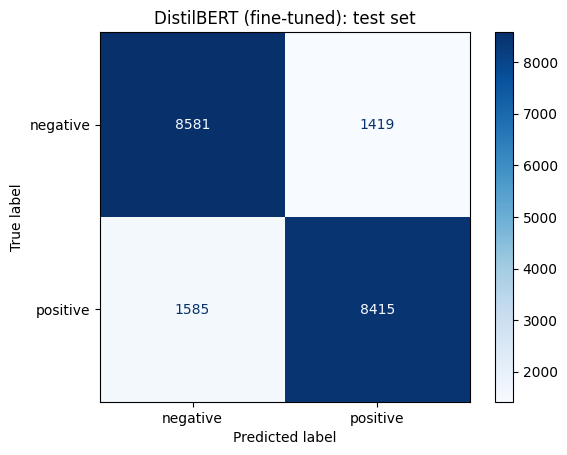

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

y_test = test_df["label"]

test_acc = accuracy_score(y_test, test_predict)
test_f1 = f1_score(y_test, test_predict, average="macro")
print(f"test accuracy:   {test_acc:.4f}")
print(f"test F1 (macro): {test_f1:.4f}")

print(classification_report(y_test, test_predict, target_names=["negative", "positive"]))

cm = confusion_matrix(y_test, test_predict)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"])
disp.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT (fine-tuned): test set")
plt.savefig("/kaggle/working/distilbert_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
predictions = test_df[["id", "tweet", "clean_tweet", "label"]].copy()
predictions["predicted"] = test_predict
predictions["prob_positive"] = prob_positive
predictions["correct"] = predictions["label"] == predictions["predicted"]

predictions.to_csv("/kaggle/working/distilbert_test_predictions.csv", index=False)

print(predictions.shape)
print("accuracy check:", predictions["correct"].mean())
predictions.head()

(20000, 7)
accuracy check: 0.8498


,id,tweet,clean_tweet,label,predicted,prob_positive,correct
0,2239206749,@disappointment http://twitpic.com/7sxp2 - You...,USER URL - you have a friday *axe*? our office...,0,0,0.034452,True
1,1690787985,dropped my laptop on the bridge ov my nose can...,dropped my laptop on the bridge ov my nose can...,0,0,0.011818,True
2,2174779878,Goin' to bed... but not without my Kradam sear...,goin' to bed... but not without my kradam sear...,1,0,0.159387,False
3,1881939153,"Friday, payday! Or more like, bill paying day","friday, payday! or more like, bill paying day",0,1,0.689362,False
4,1996378411,Um.. I want Brutal Legend so retardedly bad no...,um.. i want brutal legend so retardedly bad no...,1,0,0.463599,False
